# *You shall know a word by the **corpus** it keeps*: PubMed vs. Reuters
## Lexical and vector semantics on clinical-trial abstracts
### NLP / PLN · MEIC & MEIM · ISEL · Module 4: Semantics

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/matpato/SemShift/blob/main/notebooks/SemShift_biomedical.ipynb)

**The idea.** A word means what its context makes it mean. We let a computer read **two worlds** and learn word
meanings from scratch:

| | **PubMed 20k RCT** | **Reuters-21578** |
|---|---|---|
| What | 20,000 abstracts of randomised controlled trials | 10,788 financial news stories |
| When | trials published 1990s–2010s | 1987 |
| Size | ≈ 4.8 M words | ≈ 1.3 M words |

Then we ask both: what do ***depression***, ***delivery***, ***pressure***, ***administration***, ***positive*** mean?
In one world *depression* is a mental disorder measured with the Beck inventory; in the other it is an economic slump.
*Delivery* is a caesarean section or a shipment of wheat. And `MS` is multiple sclerosis… or Morgan Stanley's stock ticker.

| # | Learning outcome | Where |
|---|---|---|
| LO1 | Lexical semantics (synonymy, polysemy, hyponymy, meronymy) and WordNet | [§1](#s1) |
| LO2 | The distributional hypothesis | [§2](#s2) |
| LO3 | Sparse (TF-IDF, PPMI) and dense (embedding) vectors | [§3](#s3), [§4](#s4) |
| LO4 | Cosine similarity for words and documents | [§3](#s3), [§5](#s5) |
| LO5 | Word sense disambiguation vs. entity linking (biomedical abbreviations) | [§6](#s6), [§7](#s7) |
| LO6 | How word2vec/GloVe are trained, and their limitations (antonyms, OOV drugs, bias) | [§4](#s4), [§8](#s8) |
| + | Graphs: word communities, word sense *induction*, and evaluation metrics (P/R/F1, NMI, ARI, modularity) | [§9](#s9) |

**Runtime.** ≈ 8–10 minutes on a free Colab CPU (the PubMed word2vec model takes ≈ 2 min). No GPU needed.

> **Golden rule: predict before you run.** The surprises are where the learning is.

> This notebook is about **language**, not medicine: nothing here is clinical advice.

<a id="s0"></a>
## 0. Setup

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("gensim") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gensim>=4.4"], check=True)

In [2]:
import re, json, time, random, collections, warnings, os, urllib.request
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
import nltk
warnings.filterwarnings("ignore")
for pkg in ["reuters", "wordnet", "omw-1.4", "omw-2.0", "stopwords"]:
    nltk.download(pkg, quiet=True)
from nltk.corpus import reuters, wordnet as wn, stopwords
STOP = set(stopwords.words("english"))

C_P, C_R, C_W = "#7a4fd1", "#2a78d6", "#1baf7a"     # PubMed, Reuters, GloVe (Wikipedia)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#9b9a95", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 9})
T0 = time.time()

**PubMed 20k RCT** (Dernoncourt & Lee, 2017) is a public dataset of clinical-trial abstracts, one sentence per line,
each labelled with its role (BACKGROUND, OBJECTIVE, METHODS, RESULTS, CONCLUSIONS). We download it from GitHub (≈ 39 MB).

In [3]:
URL = "https://raw.githubusercontent.com/Franck-Dernoncourt/pubmed-rct/master/PubMed_20k_RCT/{}.txt"
os.makedirs("pubmed_rct", exist_ok=True)
ABSTRACTS = []                                   # list of (pmid, [(label, sentence), ...])
for split in ["train", "dev", "test"]:
    path = f"pubmed_rct/{split}.txt"
    if not os.path.exists(path):
        urllib.request.urlretrieve(URL.format(split), path)
    cur = None
    for line in open(path, encoding="utf-8"):
        line = line.rstrip("\n")
        if line.startswith("###"):
            cur = (line[3:], []); ABSTRACTS.append(cur)
        elif "\t" in line:
            label, sent = line.split("\t", 1); cur[1].append((label, sent))
print(f"{len(ABSTRACTS):,} abstracts")
print("example:", ABSTRACTS[0][1][0])

20,000 abstracts
example: ('OBJECTIVE', 'To investigate the efficacy of 6 weeks of daily low-dose oral prednisolone in improving pain , mobility , and systemic low-grade inflammation in the short term and whether the effect would be sustained at 12 weeks in older adults with moderate to severe knee osteoarthritis ( OA ) .')


In [4]:
def clean(sents):
    out = []
    for s in sents:
        t = [w.lower() for w in s if re.fullmatch(r"[A-Za-z][A-Za-z'-]*", w)]
        if len(t) > 2:
            out.append(t)
    return out

RAW = {"pubmed": [s for _, ss in ABSTRACTS for _, s in ss],
       "reuters": [" ".join(s) for s in reuters.sents()]}
SENTS = {"pubmed": clean(s.split() for s in RAW["pubmed"]), "reuters": clean(reuters.sents())}
for name, S in SENTS.items():
    print(f"{name:8s} {len(S):7,d} sentences  {sum(map(len, S)):10,d} tokens  {len({w for s in S for w in s}):7,d} word types")

pubmed   236,879 sentences   4,806,792 tokens   71,159 word types
reuters   54,225 sentences   1,326,285 tokens   29,163 word types


<a id="s1"></a>
## 1. Lexical semantics and WordNet (LO1)

**Predict:** how many noun senses does WordNet give *depression*? Which comes first, the mental one or the economic one?

In [5]:
for w in ["depression", "delivery", "administration"]:
    print(f"\n{w.upper()}")
    for i, s in enumerate(wn.synsets(w, pos="n"), 1):
        print(f"  {i:2d}. {s.name():32s} {s.definition()[:72]}")


DEPRESSION


   1. depression.n.01                  a mental state characterized by a pessimistic sense of inadequacy and a 
   2. depression.n.02                  a long-term economic state characterized by unemployment and low prices 
   3. natural_depression.n.01          a sunken or depressed geological formation
   4. depression.n.04                  sad feelings of gloom and inadequacy
   5. depression.n.05                  a period during the 1930s when there was a worldwide economic depression
   6. low.n.01                         an air mass of lower pressure; often brings precipitation
   7. depressive_disorder.n.01         a state of depression and anhedonia so severe as to require clinical int
   8. depression.n.08                  a concavity in a surface produced by pressing
   9. depression.n.09                  angular distance below the horizon (especially of a celestial object)
  10. depression.n.10                  pushing down

DELIVERY
   1. delivery.n.01                    th

Senses 1 and 2 of *depression* are **homonyms in practice** (a mental state vs. an economic state), and WordNet also has a
separate clinical sense, `depressive_disorder.n.01`. Sense distinctions are a lexicographer's choice: are
`depression.n.01` (mental state) and `depressive_disorder.n.01` (clinical) one meaning or two?

Now the **relations**. Biomedicine is full of IS-A (hyponymy) and PART-OF (meronymy) hierarchies:

In [6]:
mi = wn.synset("myocardial_infarction.n.01")
print("SYNONYMS of myocardial infarction:", mi.lemma_names())
print("HYPERNYM path:", " → ".join(s.lemma_names()[0] for s in mi.hypernym_paths()[0]))
heart = wn.synset("heart.n.02")
print("\nPART MERONYMS of the heart:", sorted(m.lemma_names()[0] for m in heart.part_meronyms()))
print("HOLONYM of the heart (it is part of):", [h.lemma_names()[0] for h in heart.part_holonyms()])
print("\nHYPONYMS of analgesic (kinds of painkiller):", sorted(h.lemma_names()[0] for h in wn.synset("analgesic.n.01").hyponyms())[:10])
print("ANTONYM of 'benign':", [a.name() for l in wn.synset("benign.a.01").lemmas() for a in l.antonyms()])
dep, eco = wn.synset("depressive_disorder.n.01"), wn.synset("depression.n.02")
print(f"\nLCS(clinical depression, economic depression) = {dep.lowest_common_hypernyms(eco)}   path sim = {dep.path_similarity(eco):.3f}")
print("Portuguese lemmas of heart.n.02:", heart.lemma_names("por"), "| of depression.n.01:", wn.synset("depression.n.01").lemma_names("por"))

SYNONYMS of myocardial infarction: ['myocardial_infarction', 'myocardial_infarct', 'MI']
HYPERNYM path: entity → abstraction → attribute → state → condition → physical_condition → pathological_state → ill_health → pathology → infarct → myocardial_infarction

PART MERONYMS of the heart: ['cardiac_muscle', 'coronary_artery', 'heart_valve', 'valve']
HOLONYM of the heart (it is part of): ['circulatory_system']

HYPONYMS of analgesic (kinds of painkiller): ['Fentanyl', 'acetaminophen', 'acetanilide', 'acetophenetidin', 'aminopyrine', 'aspirin', 'codeine', 'colchicine', 'hydromorphone_hydrochloride', 'morphine']
ANTONYM of 'benign': ['malignant']

LCS(clinical depression, economic depression) = [Synset('condition.n.01')]   path sim = 0.125


Portuguese lemmas of heart.n.02: ['Coraçao', 'coração'] | of depression.n.01: ['depressão']


**Discuss.** WordNet is a **general** dictionary. Clinical NLP relies on specialised ones: **UMLS** (a metathesaurus of
200+ vocabularies), **MeSH** (PubMed's indexing terms), **SNOMED CT** (clinical terms), **ICD** (diagnosis codes). They are
huge, but still **hand-built**: new drugs, new variants, new abbreviations appear every week. Can we learn meaning from text?

<a id="s2"></a>
## 2. The distributional hypothesis (LO2)

> *"You shall know a word by the company it keeps."* (Firth, 1957)

**Predict** the most frequent neighbours (±5 words) of *delivery* and *pressure* in each world.

In [7]:
def context_counts(sents, word, win=5):
    c = collections.Counter()
    for s in sents:
        for i, w in enumerate(s):
            if w == word:
                c.update(x for x in s[max(0, i-win):i] + s[i+1:i+1+win] if x not in STOP and x != word)
    return c

for w in ["delivery", "pressure", "administration"]:
    for name in SENTS:
        print(f"{w:15s} {name:8s}", ", ".join(x for x, _ in context_counts(SENTS[name], w).most_common(10)))
    print()

delivery        pubmed   cesarean, women, vaginal, rate, intervention, weeks, time, care, p, mode
delivery        reuters  april, may, said, tonnes, year, corn, prepared, wheat, march, season



pressure        pubmed   blood, systolic, mean, arterial, rate, diastolic, heart, p, mm, hg


pressure        reuters  said, u, upward, dollar, put, rates, market, would, could, prices

administration  pubmed   oral, drug, mg, following, compared, intravenous, study, group, patients, hours
administration  reuters  reagan, said, officials, u, would, policy, offer, congress, economic, official



*Cesarean, vaginal, preterm* vs. *wheat, tonnes, futures*; *blood, systolic* vs. *selling, prices*;
*drug, intravenous* vs. *Reagan, officials*. The meaning is already in the counts.

<a id="s3"></a>
## 3. Sparse vectors: a TF-IDF literature search engine, and PPMI words (LO3, LO4)

### 3.1 TF-IDF + cosine = PubMed search in 10 lines
Each abstract becomes a TF-IDF vector; a query becomes a vector in the same space; we rank abstracts by **cosine**.
This is the core of classic information retrieval, and of the first stage of many systematic-review tools.

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, linear_kernel

DOCS = [" ".join(s for _, s in ss) for _, ss in ABSTRACTS]
tfidf = TfidfVectorizer(stop_words="english", sublinear_tf=True, min_df=2)
X = tfidf.fit_transform(DOCS)                                    # rows are L2-normalised
print(f"{X.shape[0]:,} abstracts x {X.shape[1]:,} terms, {100*X.nnz/np.prod(X.shape):.2f}% non-zero")

def search(query, k=3):
    scores = linear_kernel(tfidf.transform([query]), X).ravel()   # = cosine (unit vectors)
    for j in np.argsort(-scores)[:k]:
        print(f"  {scores[j]:.2f}  PMID {ABSTRACTS[j][0]}  {DOCS[j][:110]}…")

for q in ["aspirin for stroke prevention", "yoga for multiple sclerosis", "cesarean delivery epidural analgesia"]:
    print("QUERY:", q); search(q)

20,000 abstracts x 32,797 terms, 0.32% non-zero
QUERY: aspirin for stroke prevention
  0.35  PMID 26283758  We compared the effect of clopidogrel plus aspirin vs aspirin alone on functional outcome and quality of life …
  0.34  PMID 25957224  The Clopidogrel in High-risk patients with Acute Non-disabling Cerebrovascular Events ( CHANCE ) trial showed …
  0.33  PMID 24503927  The mean follow-up in the clinical trials of antiplatelet drugs in the secondary prevention of ischemic athero…
QUERY: yoga for multiple sclerosis
  0.36  PMID 25395709  Multiple Sclerosis ( MS ) is a chronic and disabling disease resulting in disabilities in young and middle-age…
  0.27  PMID 24985393  To assess the efficacy of yoga for motor function , mental health , and quality of life outcomes in persons wi…
  0.26  PMID 24906582  This pilot study explores the feasibility of yoga as part of a treatment program for alcohol dependence . Eigh…
QUERY: cesarean delivery epidural analgesia
  0.38  PMID 25693331  In 

**Try it:** search for something you care about. Then try a **synonym** (*heart attack* vs. *myocardial infarction*):
TF-IDF only matches **exact words**, which is exactly the problem dense vectors solve.

In [9]:
for q in ["heart attack", "myocardial infarction"]:
    print("QUERY:", q); search(q)

QUERY: heart attack
  0.21  PMID 25628308  Limited data exists regarding the relationship between left ventricular systolic dysfunction ( LVSD ) and hear…
  0.20  PMID 25946762  The familial Mediterranean fever 50 score ( FMF50 ) score was recently devised to define response to treatment…
  0.20  PMID 26062192  To observe the differences in clinical effect on menstrual migraine between subgaleal acupoint injection with …
QUERY: myocardial infarction
  0.30  PMID 26002889  Oxygen is commonly administered to patients with ST-elevation-myocardial infarction despite previous studies s…
  0.29  PMID 25773268  The potential benefit of dual antiplatelet therapy beyond 1 year after a myocardial infarction has not been es…
  0.28  PMID 25965711  In the Effects of Postconditioning on Myocardial Reperfusion in Patients with ST-segment Elevation Myocardial …


### 3.2 Word–context PPMI
Count co-occurrences within ±2 words (10,000 most frequent words), then weight with
$\mathrm{PPMI}(w,c) = \max\left(\log_2 \frac{P(w,c)}{P(w)P_{0.75}(c)}, 0\right)$.
**Predict:** will raw counts or PPMI give better neighbours for *pressure*?

In [10]:
from sklearn.preprocessing import normalize

def cooc_matrix(sents, V=10_000, win=2):
    freq = collections.Counter(w for s in sents for w in s)
    vocab = [w for w, _ in freq.most_common(V)]; ix = {w: i for i, w in enumerate(vocab)}
    rows, cols = [], []
    for s in sents:
        ids = [ix.get(w, -1) for w in s]
        for i, a in enumerate(ids):
            if a < 0: continue
            for j in range(max(0, i-win), min(len(ids), i+win+1)):
                if j != i and ids[j] >= 0: rows.append(a); cols.append(ids[j])
    return vocab, ix, sp.coo_matrix((np.ones(len(rows), dtype=np.float32), (rows, cols)), shape=(V, V)).tocsr()

def ppmi(C, alpha=0.75):
    total = C.sum(); p_w = np.asarray(C.sum(1)).ravel() / total
    c_cnt = np.asarray(C.sum(0)).ravel() ** alpha; p_c = c_cnt / c_cnt.sum()
    M = C.tocoo(); pmi = np.log2((M.data / total) / (p_w[M.row] * p_c[M.col])); keep = pmi > 0
    return sp.csr_matrix((pmi[keep], (M.row[keep], M.col[keep])), shape=C.shape)

SPARSE = {}
for name, S in SENTS.items():
    vocab, ix, C = cooc_matrix(S); SPARSE[name] = dict(vocab=vocab, ix=ix, C=C, P=ppmi(C))
    print(f"{name:8s} non-zero: {100*C.nnz/np.prod(C.shape):.2f}%")

def sparse_nn(name, word, weight="P", k=7):
    D = SPARSE[name]; M = normalize(D[weight]); i = D["ix"][word]
    sims = (M @ M[i].T).toarray().ravel(); sims[i] = -1
    return ", ".join(D["vocab"][j] for j in np.argsort(-sims)[:k])

for w in ["pressure", "delivery", "positive"]:
    for name in SENTS:
        print(f"{w:9s} {name:8s} counts: {sparse_nn(name, w, 'C')}")
        print(f"{'':9s} {'':8s} PPMI:   {sparse_nn(name, w, 'P')}")

pubmed   non-zero: 2.38%


reuters  non-zero: 1.00%
pressure  pubmed   counts: gases, pressures, gas, flow, transfusion, peripheral, bp
                   PPMI:   pressures, bp, blood, mmhg, sbp, systolic, diastolic
pressure  reuters  counts: focus, debate, vote, impact, restrictions, attack, limits
                   PPMI:   pressures, upward, competition, demand, moves, to, revisions
delivery  pubmed   counts: measurement, implementation, assessment, recurrence, insertion, frequency, distribution
                   PPMI:   section, cesarean, birth, gestation, delivered, labor, deliveries
delivery  reuters  counts: calls, prospects, shipment, example, reasons, responsible, accounts
                   PPMI:   shipment, april, afloat, switched, effected, june, ending
positive  pubmed   counts: negative, complex, specific, diet, subsequent, stronger, good
                   PPMI:   negative, positivity, strong, favorable, inverse, significant, stronger
positive  reuters  counts: negative, basis, compromise, recomm

                   PPMI:   negative, adverse, bearish, encouraging, favorable, worse, good


<a id="s4"></a>
## 4. Dense vectors: word2vec on each world, plus GloVe (LO3, LO6)

Skip-gram with negative sampling: for every (word, context) pair in a ±5 window, a logistic regression learns to tell it
apart from 5 random words; the learned weights are 100-dimensional embeddings.
**Predict:** how long will it take on 4.8 M words?

In [11]:
from gensim.models import Word2Vec
import gensim.downloader as api

W2V = {}
for name, S in SENTS.items():
    t = time.time()
    W2V[name] = Word2Vec(S, vector_size=100, window=5, sg=1, negative=5, min_count=5,
                         epochs=10, workers=2, seed=42).wv
    print(f"{name:8s} trained in {time.time()-t:4.0f} s   vocabulary: {len(W2V[name]):,}")
t = time.time(); GLOVE = api.load("glove-wiki-gigaword-100")
print(f"GloVe (Wikipedia + news, 6B tokens): {len(GLOVE):,} words ({time.time()-t:.0f} s)")

pubmed   trained in  123 s   vocabulary: 27,014


reuters  trained in   31 s   vocabulary: 10,424


GloVe (Wikipedia + news, 6B tokens): 400,000 words (28 s)


### 4.1 The same word in three worlds

In [12]:
from IPython.display import HTML, display
def nn(kv, w, k=6):
    return ", ".join(x for x, _ in kv.most_similar(w, topn=k)) if w in kv else "— (not in vocabulary)"
def three_worlds(words):
    rows = "".join(f"<tr><td><b>{w}</b></td><td>{nn(W2V['pubmed'], w)}</td><td>{nn(W2V['reuters'], w)}</td><td>{nn(GLOVE, w)}</td></tr>" for w in words)
    display(HTML(f'''<table style="font-size:12px"><tr><th>word</th><th style="color:{C_P}">PubMed RCT</th>
      <th style="color:{C_R}">Reuters 1987</th><th style="color:{C_W}">GloVe</th></tr>{rows}</table>'''))
three_worlds(["depression", "delivery", "pressure", "administration", "recovery", "growth", "failure",
              "attack", "labor", "operation", "positive", "margin", "culture", "tender"])

word,PubMed RCT,Reuters 1987,GloVe
depression,"anxiety, depressive, somatization, delusional, inventory-ii, bdi-ii","deteriorating, disruptions, dwindling, deteriorate, rash, posing","illness, anxiety, severe, onset, schizophrenia, disorder"
delivery,"cesarean, caesarean, deliveries, breech, delivering, nonreassuring","shipment, wheats, laydays, srw, onwards, optional","deliveries, supplies, supply, dropped, crude, delivered"
pressure,"pressures, bp, paco, transpulmonary, rpp, abp","deflect, rein, nervously, dependence, grip, pushing","pressures, push, ease, despite, move, because"
administration,"nemonoxacin, subanesthetic, intravenous, administrations, injection, coadministration","reagan, aides, fda, congressmen, congressional, congress","government, policy, bush, congress, officials, clinton"
recovery,"awakening, ambulation, sensorial, ues, doms, patient-perceived","pickup, improvement, sustained, turnaround, slump, vigorous","economy, growth, economic, slowing, turnaround, improvement"
growth,"platelet-derived, insulin-like, factor-i, fibroblast, epidermal, hgf","slower, slowdown, gdp, pickup, gnp, sluggish","economy, slowing, rise, increase, decline, robust"
failure,"congestive, decompensated, hhf, multifactor, heart, ahf","predatory, dumping, honour, reintroduction, jeopardy, deadlock","failed, failing, problems, result, inability, cause"
attack,"tia, ischemic, ischaemic, stroke, attacks, cryptogenic","warship, iranian, missile, raid, platforms, persian","attacks, suicide, bombing, raid, attacked, killed"
labor,"labour, tocolysis, expectant, ripening, nulliparous, cesarean","labour, wage, housing, exceptionally, programs, urban","labour, unions, employment, union, workers, welfare"
operation,"surgery, procedure, exsufflation, harvest, tlh, rot","operations, murdochville, amusement, leaseback, bowling, retirement","operations, part, launched, mission, effort, raid"


**Discuss.**
* *depression*: *anxiety, depressive, Beck* (the Beck Depression Inventory) vs. a word Reuters barely uses.
* *failure*: *congestive, heart, decompensated* vs. *jeopardy, deadlock*. *attack*: *TIA, ischemic, stroke* vs. *warship, missile*.
* *tender*: *swollen, joints* (tender and swollen joint counts in rheumatology!) vs. a **tender offer** for shares.
* *margin*: *non-inferiority* (a trial-design margin) vs. *ratios, allowable*.
* GloVe, trained on everything, mostly follows the **most frequent** sense in general text.

> Neighbours may differ slightly between runs (multi-threaded training is not deterministic); the meanings are stable.

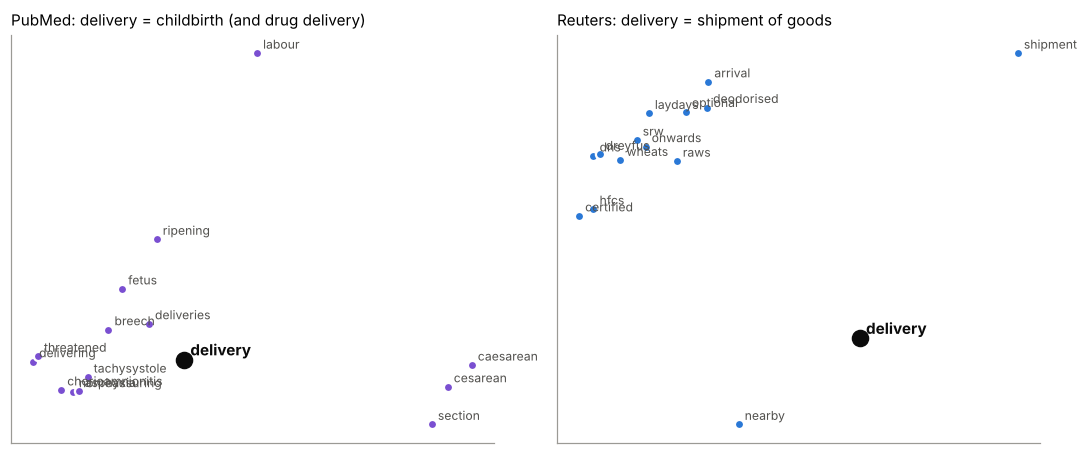

In [13]:
from sklearn.decomposition import PCA
def plot_space(ax, kv, center, color, title, k=14):
    words = [center] + [w for w, _ in kv.most_similar(center, topn=k)]
    xy = PCA(n_components=2, random_state=0).fit_transform(np.array([kv[w] for w in words]))
    ax.scatter(xy[1:, 0], xy[1:, 1], s=36, color=color, edgecolor="white", linewidth=1.5, zorder=3)
    ax.scatter(xy[0, 0], xy[0, 1], s=110, color="#0b0b0b", zorder=4)
    for (x, y), w in zip(xy, words):
        ax.annotate(w, (x, y), xytext=(4, 3), textcoords="offset points", fontsize=10 if w == center else 8,
                    color="#0b0b0b" if w == center else "#52514e", fontweight="bold" if w == center else "normal")
    ax.set_title(title, loc="left", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
plot_space(axes[0], W2V["pubmed"], "delivery", C_P, "PubMed: delivery = childbirth (and drug delivery)")
plot_space(axes[1], W2V["reuters"], "delivery", C_R, "Reuters: delivery = shipment of goods")
plt.tight_layout(); plt.show()

### 4.2 Analogies: domain knowledge for free… sometimes
**Predict:** *aspirin : stroke :: statin : ?* What will GloVe answer?

In [14]:
def analogy(kv, a, b, c, k=4):
    try:
        return ", ".join(x for x, _ in kv.most_similar(positive=[b, c], negative=[a], topn=k))
    except KeyError as e:
        return f"— ({e.args[0].split()[1]} unknown)"
for a, b, c in [("insulin", "diabetes", "levodopa"), ("heart", "cardiologist", "skin"), ("heart", "cardiac", "kidney"),
                ("knee", "arthroplasty", "hip"), ("aspirin", "stroke", "statin")]:
    print(f"{a}:{b} :: {c}:?\n   PubMed → {analogy(W2V['pubmed'], a, b, c)}\n   GloVe  → {analogy(GLOVE, a, b, c)}")

insulin:diabetes :: levodopa:?
   PubMed → parkinson, nms, schizophrenia, camptocormia
   GloVe  → gaucher, parkinson, crohn, alzheimer
heart:cardiologist :: skin:?
   PubMed → dermatologist, cleansers, veterinarians, layers
   GloVe  → dermatologist, ophthalmologist, oncologist, neurosurgeon
heart:cardiac :: kidney:?
   PubMed → renal, aki, olt, dgf
   GloVe  → renal, dialysis, liver, transplant
knee:arthroplasty :: hip:?
   PubMed → tha, thr, mini-incision, posterolateral
   GloVe  → kroncong, hip-hop, hiphop, colab
aspirin:stroke :: statin:?
   PubMed → congestive, hf, chf, adhf
   GloVe  → strokes, 7-under, bogey, hole


*insulin : diabetes :: levodopa : **parkinson*** works in both. But in GloVe *hip* is closest to **hip-hop**, and a *stroke*
is a **golf** stroke (*bogey, hole*): in general text those are the dominant senses. The PubMed model answers **THA**
(total hip arthroplasty). **Domain matters.**

<a id="s5"></a>
## 5. Highlight: a semantic-shift detector (LO4)

Align the two spaces with an orthogonal rotation (Procrustes, $Q = UV^\top$ from $\mathrm{SVD}(A^\top B)$) and measure how far
each word moves. **Predict** three words that will move a lot between finance and clinical trials.

In [15]:
P_, R_ = W2V["pubmed"], W2V["reuters"]
shared = [w for w in R_.index_to_key if w in P_.key_to_index]
A = np.array([R_[w] / np.linalg.norm(R_[w]) for w in shared]); B = np.array([P_[w] / np.linalg.norm(P_[w]) for w in shared])
U, _, Vt = np.linalg.svd(A.T @ B); Q = U @ Vt
SHIFT = dict(zip(shared, 1 - np.sum((A @ Q) * B, axis=1)))
cand = [w for w in shared if R_.get_vecattr(w, "count") >= 50 and P_.get_vecattr(w, "count") >= 50 and w not in STOP and len(w) > 2]
ranked = sorted(cand, key=SHIFT.get)
print(f"{len(shared):,} shared words, {len(cand)} frequent in both\n")
print("MOST SHIFTED:", ", ".join(ranked[::-1][:30]))
print("\nMOST STABLE: ", ", ".join(ranked[:25]))

5,313 shared words, 1119 frequent in both

MOST SHIFTED: press, common, forced, branch, sec, confidence, alone, terminal, hearing, bilateral, parent, inventory, added, solution, gold, progressive, offering, primary, sun, open, warrants, seasonal, maintenance, enhancement, bpd, warrant, producing, split, exchange, general

MOST STABLE:  would, four, lower, might, increase, higher, able, three, could, impact, improvement, five, less, although, better, six, decline, efforts, reduce, average, cause, based, important, propose, including


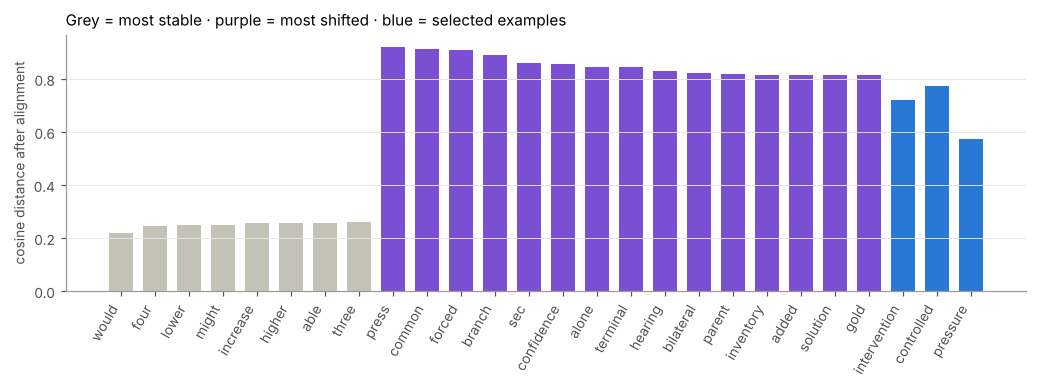

confidence    PubMed: interval, ci, adjusted, odds, hazard                    Reuters: climate, undermine, fortunes, plays, particular
intervention  PubMed: gsd-y, wait-list, interventions, program, c-map         Reuters: bd, concerted, firs, operators, fixing
hearing       PubMed: bone-anchored, vision, asnhl, sensorineural, issnhl     Reuters: testifying, subcommittee, appropriations, testified, testimony
controlled    PubMed: placebo-controlled, three-arm, single-blinded, two-arm, parallel-controlled Reuters: owned, owner, financier, formed, wealthy
terminal      PubMed: half-life, tmax, half-lives, infinity, aucinf           Reuters: alexandria, kharg, doors, landed, tumaco
branch        PubMed: coronaries, distally, bifurcation, circumflex, predilation Reuters: carteret, branches, offices, fur, postal


In [16]:
stable = ranked[:8]; top = [w for w in ranked[::-1][:15] if w not in stable]
extra = [w for w in ["confidence", "intervention", "controlled", "pressure"] if w in SHIFT and w not in top]
words = stable + top + extra; vals = [SHIFT[w] for w in words]
fig, ax = plt.subplots(figsize=(9.5, 3.6))
ax.bar(range(len(words)), vals, width=0.7, color=["#c3c2b7"] * len(stable) + [C_P] * len(top) + [C_R] * len(extra))
ax.set_xticks(range(len(words))); ax.set_xticklabels(words, rotation=60, ha="right")
ax.set_ylabel("cosine distance after alignment"); ax.grid(axis="x", visible=False)
ax.set_title("Grey = most stable · purple = most shifted · blue = selected examples", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
for w in ["confidence", "intervention", "hearing", "controlled", "terminal", "branch"]:
    if w in SHIFT: print(f"{w:13s} PubMed: {nn(P_, w, 5):55s} Reuters: {nn(R_, w, 5)}")

*confidence* (consumer confidence → **confidence interval**), *intervention* (currency-market intervention → **clinical
intervention**), *controlled* (→ randomised **controlled** trial), *hearing* (a court hearing → **hearing loss**), *terminal*
(an oil terminal → **terminal** illness), *branch* (a company branch → a **branch** of an artery). Nobody gave the model this list.
Rare words and names also move: rerun with another `seed` and keep what survives.

<a id="s6"></a>
## 6. Word sense disambiguation (LO5)

### 6.1 Which sense dominates each world?
Average the embeddings of each WordNet sense's gloss, examples and hypernyms, and compare it with the corpus vector of the
word **and its 10 nearest neighbours** (in the spirit of McCarthy et al., 2004, who score senses through a word's distributional
neighbours). Using the neighbours makes the answer more stable from one training run to the next; close calls can still flip.

In [17]:
def toks(t): return [w.lower() for w in re.findall(r"[A-Za-z]+", t)]
def signature(s, word):
    ws = toks(s.definition()) + [w for e in s.examples() for w in toks(e)] \
         + [l for h in s.hypernyms() for l in toks(" ".join(h.lemma_names()))] + toks(" ".join(s.lemma_names()))
    return [w for w in ws if w not in STOP and w != word]
def mean_vec(kv, ws):
    v = [kv[w] for w in ws if w in kv]; return np.mean(v, 0) if v else None
def cos(a, b): return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-9))
def predominant_sense(kv, word, k=10):
    # score each sense against the word AND its k nearest neighbours (more stable than the word alone)
    group = [word] + [w for w, _ in kv.most_similar(word, topn=k)]
    sc = [(np.mean([cos(kv[g], v) for g in group]), s.name(), s.definition()[:48]) for s in wn.synsets(word, "n")
          if (v := mean_vec(kv, signature(s, word))) is not None]
    return max(sc)

for w in ["delivery", "administration", "recovery", "operation", "intervention", "attack"]:
    for name in ["pubmed", "reuters"]:
        _, s, d = predominant_sense(W2V[name], w)
        print(f"{w:14s} {name:8s} → {s:28s} {d}")

delivery       pubmed   → delivery.n.02                the event of giving birth
delivery       reuters  → delivery.n.01                the act of delivering or distributing something 
administration pubmed   → administration.n.03          the act of administering medication
administration reuters  → administration.n.02          the persons (or committees or departments etc.) 
recovery       pubmed   → convalescence.n.01           gradual healing (through rest) after sickness or
recovery       reuters  → recovery.n.01                return to an original state
operation      pubmed   → operation.n.06               a medical procedure involving an incision with i
operation      reuters  → operation.n.07               a process or series of acts especially of a prac
intervention   pubmed   → treatment.n.01               care provided to improve a situation (especially
intervention   reuters  → intervention.n.01            the act of intervening (as to mediate a dispute,
attack         pu

*delivery* = birth vs. distributing goods; *administration* = **giving a drug** vs. the government;
*recovery* = **convalescence** vs. a return to an earlier state; *operation* = **surgery**; *intervention* = **treatment**.

### 6.2 Token level: 26 hand-labelled occurrences of *delivery*
WordNet's sense 1 is `delivery.n.01` (*distributing goods or mail*). In PubMed it is often **childbirth**
(`delivery.n.02`; WordNet even has a second birth sense, `delivery.n.07`), but also **drug / oxygen / vaccine delivery**
and **health-care delivery**. One Reuters sentence is a surprise: *"remarks prepared for **delivery**"* is a speech.

In [18]:
GOLD = [
{
"corpus": "reuters",
"text": "The contract provides for the delivery of 48,000 lbs, plus or minus two pct, of bulk HFCS-55 meeting specified standards regarding its physical and chemical properties.",
"gold": "delivery.n.01"
},
{
"corpus": "reuters",
"text": "Cargill Inc of Minnesota took two shipments, totalling 83,000 tonnes priced between 92.00 and 92.93 U.S. Dlrs per tonne c and f Taiwan for September 5-20 / September 10-25 delivery.",
"gold": "delivery.n.01"
},
{
"corpus": "reuters",
"text": "USDA SAYS WHEAT PURCHASED FROM FOREIGN SELLERS The U.S. Agriculture Department said private U.S. exporters reported purchases from foreign sellers of 120,000 tonnes of wheat for delivery to unknown destinations.",
"gold": "delivery.n.01"
},
{
"corpus": "reuters",
"text": "CSCE TO PUT ADDITIONAL MARGIN ON JULY COCOA A 250 dlr spot charge will be added to the New York cocoa futures, July delivery, contract starting Wednesday, March 18, the Coffee, Sugar and Cocoa Exchange said.",
"gold": "delivery.n.01"
},
{
"corpus": "reuters",
"text": "Normally Syria calls white sugar buying tenders for forward delivery, and last month's spot requirement resulted in the sale of several cargoes.",
"gold": "delivery.n.01"
},
{
"corpus": "reuters",
"text": "Sales of wheat and corn to the USSR for delivery during the fourth year of the agreement totaled 8,182, 500 tonnes -- 4,080, 500 tonnes of wheat and 4,102, 300 tonnes of corn.",
"gold": "delivery.n.01"
},
{
"corpus": "reuters",
"text": "The department noted the sales are the first reported for delivery during the fifth year of the Agreement, which began October 1,1987.",
"gold": "delivery.n.01"
},
{
"corpus": "reuters",
"text": "The March delivery ceases trading March 17, making May and July the two nearby unlimited positions.",
"gold": "delivery.n.01"
},
{
"corpus": "reuters",
"text": "\"The data we have in hand do not provide clearcut evidence that the deterioration in the trade balance has yet been reversed,\" Volcker said in remarks prepared for delivery to a luncheon for community leaders here.",
"gold": "manner_of_speaking.n.01"
},
{
"corpus": "reuters",
"text": "Delivery method will be by in-line or in-well transfer, inter-facility transfer or pumpover, or book transfer and cannot be done earlier than the tenth calendar day of the delivery month, according to the exchange.",
"gold": "delivery.n.01"
},
{
"corpus": "reuters",
"text": "The department said the cattle are for delivery May 7-June 7,1987, and the bonus awarded was 1,888.06 dlrs per head.",
"gold": "delivery.n.01"
},
{
"corpus": "reuters",
"text": "The cattle are for delivery May, 1987-October, 1988, it said.",
"gold": "delivery.n.01"
},
{
"corpus": "pubmed",
"text": "Assignment to the Project DULCE intervention led to improvements in preventive health care delivery and utilization and accelerated access to concrete supports among low-income families.",
"gold": "delivery.n.01"
},
{
"corpus": "pubmed",
"text": "We randomly assigned infants born at 25 weeks 0 days to 28 weeks 6 days of gestation to receive SLI (25 cm H2O for 15 seconds) followed by nasal continuous positive airway pressure (nCPAP) or nCPAP alone in the delivery room.",
"gold": "delivery.n.02"
},
{
"corpus": "pubmed",
"text": "Three hundred and four women (84 %) were followed until delivery.",
"gold": "delivery.n.02"
},
{
"corpus": "pubmed",
"text": "To assess the effect on mode of delivery of the routine use of labour epidural analgesia (EA) compared with analgesia on request.",
"gold": "delivery.n.02"
},
{
"corpus": "pubmed",
"text": "Poor tolerance of laryngoscopy was reported in 6.5 % with comparable distribution between anesthetic delivery methods.",
"gold": "delivery.n.01"
},
{
"corpus": "pubmed",
"text": "Further research building upon the current study in unpacking the relative strengths and weaknesses for the high and low intensity treatments would be beneficial for service delivery.",
"gold": "delivery.n.01"
},
{
"corpus": "pubmed",
"text": "To assess whether outpatient cervical ripening at 41 0/7 weeks of gestation with the nitric oxide donor isosorbide mononitrate reduces cesarean delivery rates in nulliparous women with an unfavorable cervix.",
"gold": "delivery.n.02"
},
{
"corpus": "pubmed",
"text": "We hypothesized that design differences between NCs would influence O2 delivery and ETCO2 detection.",
"gold": "delivery.n.01"
},
{
"corpus": "pubmed",
"text": "The primary outcome was glycemic control measured with hemoglobin A1c < 7 % at delivery.",
"gold": "delivery.n.02"
},
{
"corpus": "pubmed",
"text": "The most common reason for loss to follow-up was delivery of baby prior to follow-up (n = 9).",
"gold": "delivery.n.02"
},
{
"corpus": "pubmed",
"text": "Wider contextual (economic climate, unprecedented wet weather) and organisational (workload, car parking facilities) issues were identified that influenced the delivery of, and response to, the intervention.",
"gold": "delivery.n.01"
},
{
"corpus": "pubmed",
"text": "No statistically significant difference was found between the two groups in gestational weight gain, pregnancy length, mode of delivery, first and second stage of labour, perineal tear, and 1st and 5th min Apgar score.",
"gold": "delivery.n.02"
},
{
"corpus": "pubmed",
"text": "We investigated the effect of immediate delivery versus expectant monitoring on maternal and neonatal outcomes in such women.",
"gold": "delivery.n.02"
},
{
"corpus": "pubmed",
"text": "Intradermal MVA85A, a candidate vaccine against tuberculosis, induces high amounts of Ag85A-specific CD4 T cells in adults who have already received the BCG vaccine, but aerosol delivery of this vaccine might offer immunological and logistical advantages.",
"gold": "delivery.n.01"
}
]
print(collections.Counter((g["corpus"], g["gold"]) for g in GOLD))

Counter({('reuters', 'delivery.n.01'): 11, ('pubmed', 'delivery.n.02'): 8, ('pubmed', 'delivery.n.01'): 6, ('reuters', 'manner_of_speaking.n.01'): 1})


Six methods: **MFS** (WordNet sense 1), **domain MFS** (§6.1), **NLTK Lesk**, **simplified Lesk**, embedding WSD with
**general GloVe**, and embedding WSD with **domain word2vec** (PubMed vectors for PubMed sentences).
We score **coarse** senses (TRANSFER, BIRTH, SPEECH): WordNet's two birth senses are not worth fighting over.
**Predict:** will domain vectors beat GloVe on PubMed?

In [19]:
from nltk.wsd import lesk
SENSES = wn.synsets("delivery", pos="n")
COARSE = {"delivery.n.01": "TRANSFER", "delivery.n.04": "TRANSFER", "rescue.n.01": "TRANSFER",
          "delivery.n.02": "BIRTH", "delivery.n.07": "BIRTH", "manner_of_speaking.n.01": "SPEECH", "pitch.n.02": "OTHER"}
def simplified_lesk(text):
    ctx = set(toks(text)) - STOP - {"delivery"}
    return max(SENSES, key=lambda s: len(set(toks(s.definition() + " " + " ".join(s.examples()))) & ctx)).name()
def make_embedding_wsd(kv):
    SV = {s.name(): v for s in SENSES if (v := mean_vec(kv, signature(s, "delivery"))) is not None}
    def wsd(text, win=10):
        ws = toks(text); i = ws.index("delivery")
        cv = mean_vec(kv, [w for w in ws[max(0, i-win):i+win+1] if w not in STOP and w != "delivery"])
        return max(SV, key=lambda k: cos(cv, SV[k]))
    return wsd
DOMAIN_MFS = {n: predominant_sense(W2V[n], "delivery")[1] for n in W2V}
glove_wsd = make_embedding_wsd(GLOVE); domain_wsd = {n: make_embedding_wsd(W2V[n]) for n in W2V}
METHODS = {
    "MFS (WordNet)":     lambda g: "delivery.n.01",
    "domain MFS":        lambda g: DOMAIN_MFS[g["corpus"]],
    "NLTK lesk":         lambda g: lesk(toks(g["text"]), "delivery", "n").name(),
    "simplified Lesk":   lambda g: simplified_lesk(g["text"]),
    "GloVe (general)":   lambda g: glove_wsd(g["text"]),
    "domain word2vec":   lambda g: domain_wsd[g["corpus"]](g["text"]),
}
print(f"{'method':18s} {'Reuters':>8s} {'PubMed':>8s}   (coarse accuracy)")
for m, f in METHODS.items():
    acc = [np.mean([COARSE.get(f(g), "OTHER") == COARSE[g["gold"]] for g in GOLD if g["corpus"] == c]) for c in ["reuters", "pubmed"]]
    print(f"{m:18s} {acc[0]:8.2f} {acc[1]:8.2f}")

method              Reuters   PubMed   (coarse accuracy)
MFS (WordNet)          0.92     0.43
domain MFS             0.92     0.57
NLTK lesk              0.83     0.36
simplified Lesk        0.92     0.43
GloVe (general)        1.00     1.00
domain word2vec        1.00     0.64


**Discuss.**
* **MFS** is excellent on Reuters and poor on PubMed: WordNet's sense frequencies come from general text.
* The **domain MFS** (*birth*) helps, but PubMed uses *delivery* in two senses about equally: a single "most frequent" sense
  cannot be enough.
* Surprise: **general GloVe** beats the **domain** word2vec here. The sense vectors are built from WordNet glosses
  (*goods, mail, distributing*), everyday words that 4.8 M words of trial abstracts know poorly. Domain vectors know the
  domain, not the dictionary. Real clinical WSD uses **domain inventories** (UMLS) *and* domain models (e.g. BioBERT).
* 26 sentences is a toy evaluation: one sentence is ≈ 7 points.

<a id="s7"></a>
## 7. Entity linking: ambiguous abbreviations (LO5)

`MS` is **multiple sclerosis**, **mass spectrometry**, **metabolic syndrome**… and in Reuters, **Morgan Stanley**'s stock
ticker. `PD` is **Parkinson's disease**, **pharmacodynamics**, **pneumatic dilation** (achalasia) and **Phelps Dodge**.
Linking a mention to a knowledge-base entity, or to **NIL** when it is not there, is entity linking.

A tiny KB with Wikidata IDs where we verified them (`None` = look it up in §7.1):

In [20]:
KB = {'MS': [{'id': 'multiple sclerosis',
         'qid': 'Q8277',
         'name': 'multiple sclerosis',
         'desc': 'chronic autoimmune disease of the central nervous system that damages the myelin around nerve axons; '
                 'relapsing disability, lesions, neurologist, interferon, natalizumab'},
        {'id': 'mass spectrometry',
         'qid': 'Q180809',
         'name': 'mass spectrometry',
         'desc': 'analytical technique that measures the mass-to-charge ratio of ions; used with liquid chromatography '
                 'to quantify drug and metabolite concentrations in plasma and serum samples'},
        {'id': 'Morgan Stanley',
         'qid': None,
         'name': 'morgan stanley',
         'desc': 'American investment bank and financial services company in New York; shares, stock, securities, '
                 'underwriting, merger and buyout advice'}],
 'PD': [{'id': "Parkinson's disease",
         'qid': 'Q11085',
         'name': 'parkinson',
         'desc': 'neurodegenerative disorder of the brain affecting movement, with tremor, rigidity and slowness; '
                 'treated with levodopa, deep brain stimulation or lesion surgery of brain nuclei'},
        {'id': 'pharmacodynamics',
         'qid': None,
         'name': 'pharmacodynamic',
         'desc': 'branch of pharmacology studying the effects of a drug on the body, the relation between drug dose, '
                 'concentration and response'},
        {'id': 'Phelps Dodge',
         'qid': None,
         'name': 'phelps dodge',
         'desc': 'American mining company, the largest United States copper producer; copper mines, metal prices, '
                 'shares and acquisitions'}]}
MENTIONS = [
{
"corpus": "pubmed",
"mention": "MS",
"text": "Venous angioplasty is not an effective treatment for MS over the short term and may exacerbate underlying disease activity.",
"gold": "multiple sclerosis"
},
{
"corpus": "pubmed",
"mention": "MS",
"text": "Disease-specific serum free fatty acids (FFAs) were quantified using chip-based direct-infusion nanoelectrospray ionization Fourier transform ion cyclotron resonance MS.",
"gold": "mass spectrometry"
},
{
"corpus": "reuters",
"mention": "MS",
"text": "Morgan Stanley and Co <MS> rose 4-1/4 to 74-7/8.",
"gold": "Morgan Stanley"
},
{
"corpus": "pubmed",
"mention": "MS",
"text": "This trial aims to evaluate if treating non-diabetic patients with MS and LVDD with metformin improves diastolic function.",
"gold": "NIL"
},
{
"corpus": "pubmed",
"mention": "PD",
"text": "Approved by hospital ethics committee, 60 PD patients undergoing brain nuclei lesion ablation were randomly allocated into 3 groups.",
"gold": "Parkinson's disease"
},
{
"corpus": "pubmed",
"mention": "PD",
"text": "GAL-021 stimulated ventilation at the highest doses, suggesting that greater infusion rates may be required for maximum PD effects.",
"gold": "pharmacodynamics"
},
{
"corpus": "reuters",
"mention": "PD",
"text": "Analysts said Phelps Dodge Corp <PD> will be a strong performer because it is the largest U.S. copper producer.",
"gold": "Phelps Dodge"
},
{
"corpus": "pubmed",
"mention": "PD",
"text": "Although both treatments resulted in significant improvements in dysphagia scores, LM was significantly favored over PD after 1 and 3 years.",
"gold": "NIL"
}
]
for m in MENTIONS: print(f"[{m['corpus']:7s}] {m['mention']:3s} gold = {m['gold']:20s} | {m['text'][:80]}")

[pubmed ] MS  gold = multiple sclerosis   | Venous angioplasty is not an effective treatment for MS over the short term and 
[pubmed ] MS  gold = mass spectrometry    | Disease-specific serum free fatty acids (FFAs) were quantified using chip-based 
[reuters] MS  gold = Morgan Stanley       | Morgan Stanley and Co <MS> rose 4-1/4 to 74-7/8.
[pubmed ] MS  gold = NIL                  | This trial aims to evaluate if treating non-diabetic patients with MS and LVDD w
[pubmed ] PD  gold = Parkinson's disease  | Approved by hospital ethics committee, 60 PD patients undergoing brain nuclei le
[pubmed ] PD  gold = pharmacodynamics     | GAL-021 stimulated ventilation at the highest doses, suggesting that greater inf
[reuters] PD  gold = Phelps Dodge         | Analysts said Phelps Dodge Corp <PD> will be a strong performer because it is th
[pubmed ] PD  gold = NIL                  | Although both treatments resulted in significant improvements in dysphagia score


**Priors from the corpus itself.** In each corpus, among the sentences that contain the abbreviation, count how often each
entity's full name also appears (+0.5 smoothing). This is how real linkers estimate $P(e \mid m)$ from Wikipedia anchor
texts, here from our own corpora.

In [21]:
def corpus_prior(corpus, m):
    S = [s.lower() for s in RAW[corpus] if re.search(rf"\b{m}\b", s)]
    c = {e["id"]: sum(e["name"] in s for s in S) + 0.5 for e in KB[m]}; t = sum(c.values())
    return {k: v / t for k, v in c.items()}
PRIOR = {(c, m): corpus_prior(c, m) for c in RAW for m in KB}
for (c, m), p in PRIOR.items():
    print(f"P(e | {m}, {c:7s}) =", {k: round(v, 2) for k, v in p.items()})

P(e | MS, pubmed ) = {'multiple sclerosis': 0.77, 'mass spectrometry': 0.22, 'Morgan Stanley': 0.01}
P(e | PD, pubmed ) = {"Parkinson's disease": 0.74, 'pharmacodynamics': 0.26, 'Phelps Dodge': 0.0}
P(e | MS, reuters) = {'multiple sclerosis': 0.09, 'mass spectrometry': 0.09, 'Morgan Stanley': 0.82}
P(e | PD, reuters) = {"Parkinson's disease": 0.09, 'pharmacodynamics': 0.09, 'Phelps Dodge': 0.82}


Five linkers: **prior only**; **dense** context with GloVe and with PubMed vectors; **dense + NIL** (NIL when the sentence
shares no word with any candidate's name or description); and **prior + dense + NIL** (score = ½·prior + ½·cosine).
**Predict:** which mentions will the prior get wrong?

In [22]:
desc_tfidf = TfidfVectorizer(stop_words="english").fit([e["id"] + " " + e["desc"] for c in KB.values() for e in c] + [m["text"] for m in MENTIONS])
def ctx(m): return [w for w in toks(m["text"]) if w != m["mention"].lower() and w not in STOP]
def dense(m, e, kv): return cos(mean_vec(kv, ctx(m)), mean_vec(kv, [w for w in toks(e["desc"]) if w not in STOP]))
def no_evidence(m):
    text = re.sub(rf"\b{m['mention']}\b", " ", m["text"])
    return max(float(cosine_similarity(desc_tfidf.transform([text]), desc_tfidf.transform([e["id"] + " " + e["desc"]]))[0, 0])
               for e in KB[m["mention"]]) == 0
def link(m, method):
    cands, pr = KB[m["mention"]], PRIOR[(m["corpus"], m["mention"])]
    if method == "prior":        return max(cands, key=lambda e: pr[e["id"]])["id"]
    if method == "dense GloVe":  return max(cands, key=lambda e: dense(m, e, GLOVE))["id"]
    if method == "dense PubMed": return max(cands, key=lambda e: dense(m, e, W2V["pubmed"]))["id"]
    if method == "dense+NIL":    return "NIL" if no_evidence(m) else link(m, "dense GloVe")
    if method == "prior+dense+NIL":
        return "NIL" if no_evidence(m) else max(cands, key=lambda e: 0.5 * pr[e["id"]] + 0.5 * dense(m, e, GLOVE))["id"]
LINKERS = ["prior", "dense GloVe", "dense PubMed", "dense+NIL", "prior+dense+NIL"]
acc = collections.Counter()
W = 21
print(f"{'gold':{W}s}" + "".join(f"{l:{W}s}" for l in LINKERS))
for m in MENTIONS:
    preds = [link(m, l) for l in LINKERS]; acc.update({l: p == m["gold"] for l, p in zip(LINKERS, preds)})
    print(f"{m['gold']:{W}s}" + "".join(f"{p:{W}s}" for p in preds))
print("\naccuracy:", {l: f"{acc[l]}/{len(MENTIONS)}" for l in LINKERS})

gold                 prior                dense GloVe          dense PubMed         dense+NIL            prior+dense+NIL      
multiple sclerosis   multiple sclerosis   multiple sclerosis   multiple sclerosis   multiple sclerosis   multiple sclerosis   
mass spectrometry    multiple sclerosis   mass spectrometry    mass spectrometry    mass spectrometry    multiple sclerosis   
Morgan Stanley       Morgan Stanley       Morgan Stanley       mass spectrometry    Morgan Stanley       Morgan Stanley       
NIL                  multiple sclerosis   multiple sclerosis   multiple sclerosis   NIL                  NIL                  
Parkinson's disease  Parkinson's disease  pharmacodynamics     Parkinson's disease  pharmacodynamics     Parkinson's disease  
pharmacodynamics     Parkinson's disease  pharmacodynamics     pharmacodynamics     pharmacodynamics     Parkinson's disease  
Phelps Dodge         Phelps Dodge         Phelps Dodge         Phelps Dodge         Phelps Dodge         Phelps

**Discuss.**
* **Domain priors** link the Reuters tickers right (*MS* → Morgan Stanley) and the common clinical senses right, but always
  miss the **minority** senses (*mass spectrometry*, *pharmacodynamics*): the EL twin of MFS.
* **Dense context** finds minority senses but never says NIL, and averaged vectors are noisy on short, technical sentences.
* *"patients with **MS** and LVDD … metformin"*: **metabolic syndrome**, not in our KB → NIL. KBs are always incomplete.
* No linker wins everywhere. Real biomedical systems add a powerful clue: the **definition in the same abstract**
  (*"multiple sclerosis (MS)"*, Schwartz & Hearst, 2003): *one sense per discourse*. See challenge 3.

### 7.1 Live: candidates from Wikidata (needs internet; works on Colab)
Fill in the `None` IDs of the KB.

In [23]:
import urllib.parse
def wikidata_candidates(mention, k=5):
    url = "https://www.wikidata.org/w/api.php?" + urllib.parse.urlencode(
        dict(action="wbsearchentities", search=mention, language="en", format="json", limit=k, type="item"))
    req = urllib.request.Request(url, headers={"User-Agent": "SemShift-tutorial/1.0 (NLP course, ISEL)"})
    with urllib.request.urlopen(req, timeout=10) as r:
        return [(c["id"], c.get("label", ""), c.get("description", "")) for c in json.load(r)["search"]]
try:
    for q in ["Morgan Stanley", "pharmacodynamics", "Phelps Dodge", "metabolic syndrome"]:
        print(f"\n{q}:"); [print(f"   {i:10s} {l:28s} {d}") for i, l, d in wikidata_candidates(q, 3)]
except Exception as e:
    print("Wikidata not reachable from here (offline?):", type(e).__name__)

(Run this cell on Colab: it queries the live Wikidata API.)


<a id="s8"></a>
## 8. Limitations of static embeddings (LO6)

### 8.1 Antonyms, polysemy and out-of-vocabulary drugs
**Predict:** in PubMed, what is the cosine between *positive* and *negative*?

In [24]:
for a, b in [("positive", "negative"), ("increase", "decrease"), ("benign", "malignant"), ("high", "low")]:
    print(f"cos({a}, {b}):  PubMed {W2V['pubmed'].similarity(a, b):.2f}   GloVe {GLOVE.similarity(a, b):.2f}")
print("\nGloVe  cold →", nn(GLOVE, "cold", 6))
print("GloVe  cold + virus →", ", ".join(w for w, _ in GLOVE.most_similar(positive=["cold", "virus"], topn=6)))
print("GloVe  culture →", nn(GLOVE, "culture", 6), "\nPubMed culture →", nn(W2V["pubmed"], "culture", 6))
print()
for d in ["metformin", "levodopa", "sitagliptin", "dapagliflozin", "ticagrelor", "nemonoxacin"]:
    print(f"{d:14s} in GloVe: {str(d in GLOVE):5s}  in PubMed: {d in W2V['pubmed']}")

cos(positive, negative):  PubMed 0.88   GloVe 0.81
cos(increase, decrease):  PubMed 0.84   GloVe 0.88
cos(benign, malignant):  PubMed 0.52   GloVe 0.71
cos(high, low):  PubMed 0.90   GloVe 0.82

GloVe  cold → warm, dry, hot, cool, chilly, winter
GloVe  cold + virus → flu, disease, strain, spread, outbreak, fever
GloVe  culture → cultural, cultures, traditions, tradition, religion, history 
PubMed culture → cultures, smears, u-pcr, rdt, mrs-pcr, histopathology

metformin      in GloVe: True   in PubMed: True
levodopa       in GloVe: True   in PubMed: True
sitagliptin    in GloVe: False  in PubMed: True
dapagliflozin  in GloVe: False  in PubMed: True
ticagrelor     in GloVe: False  in PubMed: True
nemonoxacin    in GloVe: False  in PubMed: True


* *positive* and *negative* are each other's **nearest neighbours** (cos ≈ 0.9): they occur in identical contexts
  (*test was ___*). For a clinical system, confusing a positive and a negative result is the worst possible error.
* *cold* means temperature in GloVe; you must push it (*+ virus*) to reach the illness. *culture* = society vs. **bacterial culture**.
* **OOV**: GloVe (frozen in 2014) has never seen *sitagliptin* or *ticagrelor*. Biomedical vocabularies grow every week:
  that is why fastText (sub-words) and domain models (BioWordVec, BioBERT, PubMedBERT) exist.

### 8.2 Bias: whose language did the model learn?
**Predict:** which healthcare occupations will GloVe place on the *she* side?

PubMed: count(he) = 134, count(she) = 20, count(men) = 2,040, count(women) = 6,311


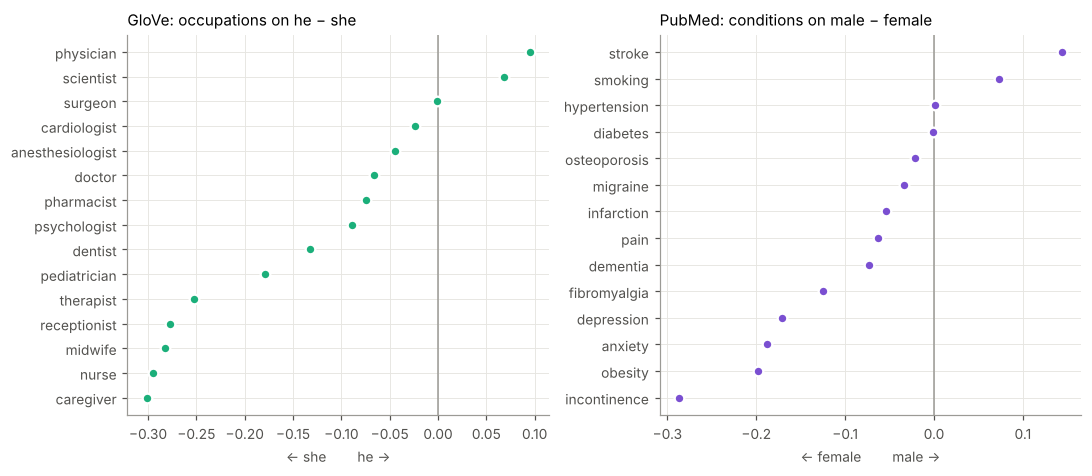

In [25]:
def proj(kv, a, b, words):
    d = kv[a] - kv[b]; d /= np.linalg.norm(d)
    return {w: float(kv[w] @ d / np.linalg.norm(kv[w])) for w in words if w in kv}
OCC = ["nurse", "midwife", "caregiver", "receptionist", "therapist", "pediatrician", "dentist", "pharmacist",
       "psychologist", "doctor", "anesthesiologist", "cardiologist", "surgeon", "scientist", "physician"]
COND = ["incontinence", "obesity", "anxiety", "depression", "fibromyalgia", "dementia", "osteoporosis", "pain",
        "hypertension", "diabetes", "migraine", "infarction", "smoking", "stroke"]
po, pc = proj(GLOVE, "he", "she", OCC), proj(W2V["pubmed"], "male", "female", COND)
print(f"PubMed: count(he) = {W2V['pubmed'].get_vecattr('he', 'count')}, count(she) = {W2V['pubmed'].get_vecattr('she', 'count')}, "
      f"count(men) = {W2V['pubmed'].get_vecattr('men', 'count'):,}, count(women) = {W2V['pubmed'].get_vecattr('women', 'count'):,}")
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, P, color, title, xl in [(axes[0], po, C_W, "GloVe: occupations on he − she", "← she        he →"),
                                (axes[1], pc, C_P, "PubMed: conditions on male − female", "← female        male →")]:
    ws = sorted(P, key=P.get); y = np.arange(len(ws))
    ax.axvline(0, color="#9b9a95", linewidth=1)
    ax.scatter([P[w] for w in ws], y, s=40, color=color, edgecolor="white", linewidth=1.5, zorder=3)
    ax.set_yticks(y); ax.set_yticklabels(ws); ax.set_xlabel(xl); ax.set_title(title, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

**Discuss.**
* GloVe puts *caregiver, nurse, midwife, receptionist* on the *she* side and *physician, scientist* on the *he* side: an
  **occupational stereotype** learned from text. Used to rank CVs for a hospital, it would discriminate.
* The PubMed panel is harder to judge: *incontinence, osteoporosis, depression, anxiety* are diagnosed more often in women,
  and *smoking, stroke* lean male. Some of this is **real epidemiology**, some may reflect **who gets studied or diagnosed**.
  Heart disease in women is a documented example of under-recognition. Association is not bias by itself: the
  harm comes from how a model is used.
* Trial abstracts almost never say *she* (20 times vs. 134 *he*): they talk about *women* and *patients*. Probing bias needs
  probes that fit the domain.

<a id="s9"></a>
## 9. From vectors to graphs, and how to measure what we built

So far each word was a point in space. Connect each point to its nearest neighbours and you get a **graph**: communities,
hubs and paths appear, and graph algorithms can **discover senses without a dictionary**. Then we evaluate everything
with the metrics used in real papers.

### 9.1 A word graph of clinical-trial language
Nodes: the 4,000 most frequent PubMed words (no stopwords). Edges: each word → its 10 nearest neighbours with cosine > 0.55.
Communities: the **Louvain** algorithm, which maximises **modularity** $Q$ (how much denser the edges are inside the
communities than expected by chance; $Q > 0.3$ is already clear structure).

**Predict:** what will the communities be about?

In [26]:
import networkx as nx
from networkx.algorithms import community as nxc

kvP = W2V["pubmed"]
VOC = [w for w in kvP.index_to_key[:4000] if w not in STOP and len(w) > 2]
Xw = np.array([kvP[w] / np.linalg.norm(kvP[w]) for w in VOC]); Sw = Xw @ Xw.T; np.fill_diagonal(Sw, -1)
WG = nx.Graph()
for i, w in enumerate(VOC):
    for j in np.argsort(-Sw[i])[:10]:
        if Sw[i, j] > 0.55:
            WG.add_edge(w, VOC[j], weight=float(Sw[i, j]))
COMS = sorted(nxc.louvain_communities(WG, weight="weight", seed=1), key=len, reverse=True)
print(f"{WG.number_of_nodes():,} nodes, {WG.number_of_edges():,} edges, {len(COMS)} communities, "
      f"modularity Q = {nxc.modularity(WG, COMS, weight='weight'):.2f}\n")
for c in COMS[:10]:
    top = sorted(c, key=lambda w: -kvP.get_vecattr(w, "count"))[:10]
    print(f"{len(c):4d} words: {', '.join(top)}")

3,576 nodes, 16,868 edges, 36 communities, modularity Q = 0.77

 423 words: effects, effect, efficacy, may, safety, effective, also, however, showed, whether
 332 words: outcomes, levels, weight, index, level, diabetes, serum, body, type, plasma
 290 words: risk, blood, pressure, incidence, acute, hospital, chronic, mortality, heart, duration
 266 words: intervention, pain, score, scores, quality, scale, activity, physical, life, visual
 257 words: care, health, data, children, among, results, patient, standard, studies, population
 201 words: training, exercise, program, functional, volume, muscle, sessions, bone, knee, resistance
 179 words: compared, associated, respectively, analysis, versus, disease, test, ratio, interval, confidence
 170 words: dose, daily, oral, plus, combined, alone, combination, administration, doses, addition
 152 words: cancer, overall, survival, breast, chemotherapy, complete, lung, stage, advanced, prostate
 140 words: patients, two, participants, years, r

The communities are the **topics of clinical trials**: dosing and administration, cardiovascular risk, oncology, exercise
and rehabilitation, trial design (*group, control, baseline, follow-up*)… none of them labelled by hand. This is the idea
behind **knowledge graphs** built from literature: nodes are concepts, edges come from co-occurrence or similarity.

### 9.2 Word sense *induction*: let the graph find the senses of *delivery*
WSD (§6) chose among senses that WordNet gave us. **Word sense induction** discovers the senses from data:
1. take **every occurrence** of *delivery* in both corpora (≈ 1,350 sentences, plus our 26 labelled ones);
2. represent each occurrence by its **context vector** (average GloVe vector of ±10 content words);
3. link each occurrence to its 10 most similar occurrences (cosine) → an **occurrence graph**;
4. find communities (Louvain): **each community is an induced sense**.

**Predict:** how many senses will the graph find? Will they match WordNet's?

In [27]:
OCC = [("pubmed", s, None) for s in RAW["pubmed"] if re.search(r"\bdelivery\b", s)] + \
      [("reuters", s, None) for s in RAW["reuters"] if re.search(r"\bdelivery\b", s)] + \
      [(g["corpus"], g["text"], COARSE[g["gold"]]) for g in GOLD]          # the labelled ones, for evaluation

def occ_vector(text, kv=GLOVE, win=10):
    ws = toks(text); i = ws.index("delivery") if "delivery" in ws else 0
    return mean_vec(kv, [w for w in ws[max(0, i-win):i+win+1] if w not in STOP and w != "delivery"])

NODES, VECS = [], []
for o in OCC:
    v = occ_vector(o[1])
    if v is not None: NODES.append(o); VECS.append(v / np.linalg.norm(v))
Xo = np.array(VECS); So = Xo @ Xo.T; np.fill_diagonal(So, -1)
OG = nx.Graph(); OG.add_nodes_from(range(len(NODES)))
for i in range(len(NODES)):
    for j in np.argsort(-So[i])[:10]:
        OG.add_edge(i, int(j), weight=float(So[i, j]))
SENSES_IND = sorted(nxc.louvain_communities(OG, weight="weight", seed=1, resolution=0.5), key=len, reverse=True)
CLUSTER = {n: k for k, c in enumerate(SENSES_IND) for n in c}
print(f"{len(NODES):,} occurrences, {OG.number_of_edges():,} edges → {len(SENSES_IND)} induced senses, "
      f"Q = {nxc.modularity(OG, SENSES_IND, weight='weight'):.2f}\n")
for k, c in enumerate(SENSES_IND):
    corp = collections.Counter(NODES[i][0] for i in c)
    words = collections.Counter(w for i in c for w in set(toks(NODES[i][1])) if w not in STOP and w != "delivery" and len(w) > 2)
    print(f"sense {k}: {len(c):4d} occurrences ({corp['pubmed']} PubMed, {corp['reuters']} Reuters)  "
          f"→ {', '.join(w for w, _ in words.most_common(8))}")

1,383 occurrences, 11,364 edges → 4 induced senses, Q = 0.57

sense 0:  443 occurrences (434 PubMed, 9 Reuters)  → intervention, care, health, study, trial, based, group, treatment
sense 1:  440 occurrences (437 PubMed, 3 Reuters)  → women, cesarean, weeks, group, pregnancy, vaginal, groups, rate
sense 2:  302 occurrences (301 PubMed, 1 Reuters)  → cesarean, patients, randomized, women, study, insulin, anesthesia, spinal
sense 3:  198 occurrences (4 PubMed, 194 Reuters)  → said, tonnes, dlrs, april, may, year, per, department


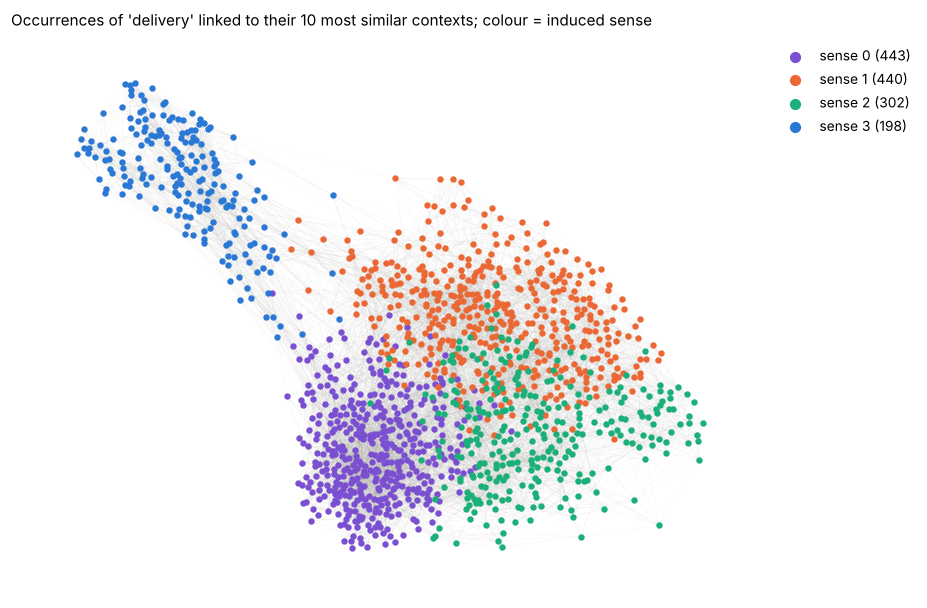

In [28]:
pos = nx.spring_layout(OG, seed=3, k=0.08, iterations=60, weight="weight")
PALETTE = ["#7a4fd1", "#eb6834", "#1baf7a", "#2a78d6", "#c2410c", "#6b7280", "#d946ef", "#0891b2"]
fig, ax = plt.subplots(figsize=(8.5, 5.6))
nx.draw_networkx_edges(OG, pos, ax=ax, width=0.2, alpha=0.15, edge_color="#9b9a95")
for k, c in enumerate(SENSES_IND):
    c = list(c)
    ax.scatter([pos[i][0] for i in c], [pos[i][1] for i in c], s=10, color=PALETTE[k % len(PALETTE)],
               label=f"sense {k} ({len(c)})", zorder=3)
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
for side in ["left", "bottom"]: ax.spines[side].set_visible(False)
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False, markerscale=2)
ax.set_title("Occurrences of 'delivery' linked to their 10 most similar contexts; colour = induced sense", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

**Discuss.** Read the top words of each induced sense. In our run the graph found four: **health-care / intervention
delivery**, **childbirth**, a community mixing **cesarean anaesthesia with drug and insulin delivery** (an epidural *is* drug
delivery around a birth), and **commodity delivery**, almost only Reuters. These are **usage senses**, not dictionary
senses: WordNet's single "*distributing something*" covers wheat, insulin and health services alike. Which inventory is
"right" depends on the application: a pharmacovigilance system needs *drug delivery* as a sense of its own; a
lexicographer may not.

Louvain has a `resolution` parameter: try `1.0` or `1.5`. More communities = finer senses. How many senses does *delivery* "really" have?

### 9.3 Clustering metrics: how close are induced senses to our gold labels?
We cannot compute accuracy directly (cluster 3 has no name), so we use measures that compare **two partitions**:
* **purity**: label each cluster with its majority gold sense, then count the fraction labelled correctly (1 = perfect; it
  rewards many small clusters, so read it together with the next two);
* **NMI** (normalised mutual information): how much knowing the cluster tells you about the gold sense (0 = nothing, 1 = everything);
* **ARI** (adjusted Rand index): agreement on *pairs* of occurrences, corrected for chance (0 = random, 1 = perfect).

In [29]:
from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score
gi = [i for i, o in enumerate(NODES) if o[2] is not None]
y_gold = [NODES[i][2] for i in gi]; y_clu = [CLUSTER[i] for i in gi]
purity = sum(collections.Counter(g for g, c in zip(y_gold, y_clu) if c == k).most_common(1)[0][1]
             for k in set(y_clu)) / len(gi)
print(f"on the {len(gi)} labelled occurrences:  purity = {purity:.2f}   NMI = {normalized_mutual_info_score(y_gold, y_clu):.2f}   "
      f"ARI = {adjusted_rand_score(y_gold, y_clu):.2f}\n")
print("gold sense × induced sense:")
tab = collections.Counter(zip(y_gold, y_clu))
print("            " + "".join(f"s{k:<5d}" for k in range(len(SENSES_IND))))
for g in ["BIRTH", "TRANSFER", "SPEECH"]:
    print(f"{g:10s}  " + "".join(f"{tab.get((g, k), 0):<6d}" for k in range(len(SENSES_IND))))

on the 26 labelled occurrences:  purity = 0.88   NMI = 0.49   ARI = 0.32

gold sense × induced sense:
            s0    s1    s2    s3    
BIRTH       0     5     3     0     
TRANSFER    5     0     2     10    
SPEECH      0     0     0     1     


Read the table row by row: each gold sense is **spread over several induced senses** (a difference of *grain*), and
some clusters mix gold senses (real errors, often short sentences whose context says little). Moderate NMI/ARI is the
typical result of comparing usage-based senses with a dictionary inventory.

### 9.4 Classification metrics for WSD and entity linking
Accuracy hides *which* senses fail. With unbalanced classes (8 BIRTH vs. 1 SPEECH) we need per-class **precision**
($\frac{TP}{TP+FP}$: when I say BIRTH, am I right?), **recall** ($\frac{TP}{TP+FN}$: do I find all the BIRTHs?) and their
harmonic mean **F1**, averaged as **macro** (each class counts the same) or **weighted** (by class size).

In [30]:
from sklearn.metrics import classification_report, confusion_matrix
y_true = [COARSE[g["gold"]] for g in GOLD]
for m in ["MFS (WordNet)", "GloVe (general)"]:
    y_pred = [COARSE.get(METHODS[m](g), "OTHER") for g in GOLD]
    print(f"===== {m} (all 26 sentences) =====")
    print(classification_report(y_true, y_pred, labels=["BIRTH", "TRANSFER", "SPEECH"], zero_division=0, digits=2))

===== MFS (WordNet) (all 26 sentences) =====
              precision    recall  f1-score   support

       BIRTH       0.00      0.00      0.00         8
    TRANSFER       0.65      1.00      0.79        17
      SPEECH       0.00      0.00      0.00         1

    accuracy                           0.65        26
   macro avg       0.22      0.33      0.26        26
weighted avg       0.43      0.65      0.52        26

===== GloVe (general) (all 26 sentences) =====
              precision    recall  f1-score   support

       BIRTH       1.00      1.00      1.00         8
    TRANSFER       1.00      1.00      1.00        17
      SPEECH       1.00      1.00      1.00         1

    accuracy                           1.00        26
   macro avg       1.00      1.00      1.00        26
weighted avg       1.00      1.00      1.00        26



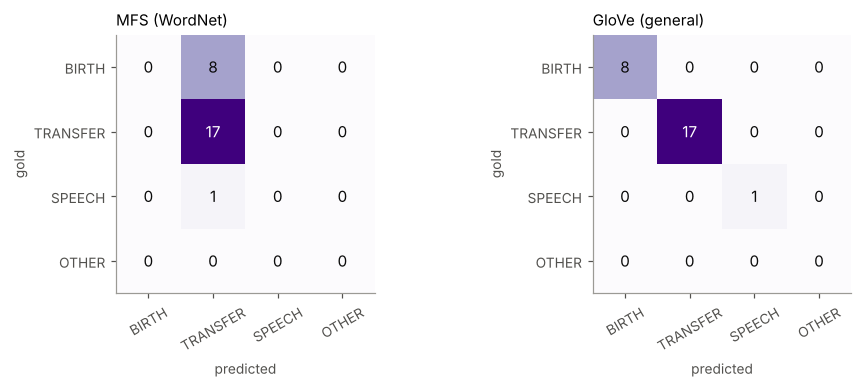

In [31]:
labels = ["BIRTH", "TRANSFER", "SPEECH", "OTHER"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, m in zip(axes, ["MFS (WordNet)", "GloVe (general)"]):
    cm = confusion_matrix(y_true, [COARSE.get(METHODS[m](g), "OTHER") for g in GOLD], labels=labels)
    ax.imshow(cm, cmap="Purples"); ax.grid(False)
    ax.set_xticks(range(4)); ax.set_xticklabels(labels, rotation=30); ax.set_yticks(range(4)); ax.set_yticklabels(labels)
    for (r, c), v in np.ndenumerate(cm):
        ax.text(c, r, v, ha="center", va="center", color="white" if v > cm.max() / 2 else "#0b0b0b", fontsize=10)
    ax.set_xlabel("predicted"); ax.set_ylabel("gold"); ax.set_title(m, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

MFS always answers TRANSFER: **recall 1.0** for TRANSFER (it finds them all) but **recall 0** for BIRTH, and its
TRANSFER precision is only the share of TRANSFER in the data. Accuracy alone (17/26 = 0.65) would not tell you that it is
useless for obstetrics; the macro F1 does.

For **entity linking**, NIL is a class of its own, and the two error types have different costs:
* **NIL precision**: when the system says "not in the KB", is that true? (low → it throws away real links);
* **NIL recall**: does it catch the mentions that are not in the KB? (low → it invents links, e.g. *metabolic syndrome* → *multiple sclerosis*).

In [32]:
y_true_el = [m["gold"] for m in MENTIONS]
for l in ["prior", "dense+NIL"]:
    y_pred_el = [link(m, l) for m in MENTIONS]
    print(f"===== {l} =====")
    print(classification_report(y_true_el, y_pred_el, zero_division=0, digits=2))

===== prior =====
                     precision    recall  f1-score   support

     Morgan Stanley       1.00      1.00      1.00         1
                NIL       0.00      0.00      0.00         2
Parkinson's disease       0.33      1.00      0.50         1
       Phelps Dodge       1.00      1.00      1.00         1
  mass spectrometry       0.00      0.00      0.00         1
 multiple sclerosis       0.33      1.00      0.50         1
   pharmacodynamics       0.00      0.00      0.00         1

           accuracy                           0.50         8
          macro avg       0.38      0.57      0.43         8
       weighted avg       0.33      0.50      0.38         8

===== dense+NIL =====
                     precision    recall  f1-score   support

     Morgan Stanley       1.00      1.00      1.00         1
                NIL       1.00      1.00      1.00         2
Parkinson's disease       0.00      0.00      0.00         1
       Phelps Dodge       1.00      1.00 

### 9.5 Which metric for which question?

| question | metric |
|---|---|
| Is the WSD / EL system right overall? | accuracy (only with balanced classes) |
| Does it work for **rare** senses / entities? | per-class recall, **macro F1** |
| Can I trust it when it says *X*? | per-class precision |
| Does it know when an entity is **not** in the KB? | NIL precision and recall |
| Do induced senses match a gold inventory? | purity, **NMI**, **ARI** |
| Is there community structure in the graph? | **modularity** $Q$ |
| Do embeddings agree with human similarity judgements? | **Spearman ρ** (biomedical sets: UMNSRS, MayoSRS) |
| Can the graph predict missing links (drug → disease)? | AUC, **Hits@k**, **MRR** |

**Challenge.** Turn the word graph into a small **knowledge graph**: link drug and disease names in the abstracts,
connect a drug to a disease when they co-occur in the same abstract (weight = PMI), hide 20 % of the edges and measure how
well cosine similarity of the embeddings recovers them (Hits@10, MRR).

<a id="s10"></a>
## 10. Wrap-up

| LO | What you saw today |
|---|---|
| LO1 | WordNet senses of *depression, delivery, administration*; synonyms, hypernyms, meronyms of the heart, antonyms; UMLS/MeSH/SNOMED in practice |
| LO2 | The neighbours of *delivery* and *pressure* reveal two worlds |
| LO3 | TF-IDF literature search; PPMI (> 98 % zeros); word2vec on 4.8 M words in ≈ 2 min; GloVe |
| LO4 | Cosine for search, neighbours, sense vectors, entity descriptions, aligned spaces |
| LO5 | WSD of *delivery* (MFS fails in PubMed) vs. entity linking of `MS`/`PD` (priors, context, NIL) |
| LO6 | antonyms (*positive/negative*), polysemy (*cold*), OOV drugs, and bias |
| + | a word graph of trial topics; senses of *delivery* induced by a graph; precision/recall/F1, NIL, purity/NMI/ARI |

**Takeaway:** *a word vector is a summary of a corpus*. In clinical NLP the corpus decides whether *positive* is good news,
whether *delivery* is a baby, and whether `MS` is a disease or a stock ticker.

### Challenges
1. **Window size.** Retrain PubMed with `window=2` and `window=10`. Which gives *similar* (synonyms, drugs of the same class) and which *related* (disease drug) neighbours?
2. **Drug classes.** Find the nearest neighbours of *metformin*, *atorvastatin*, *ibuprofen*. Do they group by class?
3. **One sense per discourse.** For each `MS` / `PD` mention, look for a definition *"X Y (MS)"* in the same abstract and use it to link. How many errors disappear?
4. **Negation.** Find sentences with *no evidence of* / *negative for*. Why does a bag of words or an averaged vector miss negation?
5. **A third world.** Add the Brown corpus (`nltk.corpus.brown`) and compare *depression, delivery, culture* across three corpora.

### References
* Dernoncourt & Lee (2017). *PubMed 200k RCT: a dataset for sequential sentence classification in medical abstracts.* IJCNLP.
* Jurafsky & Martin, *Speech and Language Processing* (3rd ed. draft), ch. 6 and Appendix G.
* Mikolov et al. (2013); Pennington et al. (2014); Levy, Goldberg & Dagan (2015).
* McCarthy et al. (2004) *Finding predominant word senses in untagged text.* ACL.
* Hamilton, Leskovec & Jurafsky (2016) *Diachronic word embeddings reveal statistical laws of semantic change.* ACL.
* Schwartz & Hearst (2003) *A simple algorithm for identifying abbreviation definitions in biomedical text.* PSB.
* Bodenreider (2004) *The Unified Medical Language System (UMLS).* Nucleic Acids Research.
* Lee et al. (2020) *BioBERT.* Bioinformatics; Bolukbasi et al. (2016) NeurIPS.
* Blondel et al. (2008) *Fast unfolding of communities in large networks* (Louvain). J. Stat. Mech.
* Navigli (2009) *Word sense disambiguation: a survey* (sense induction, §5). ACM Computing Surveys.

In [33]:
print(f"Total runtime: {(time.time()-T0)/60:.1f} min")

Total runtime: 3.8 min
